# 09 처음 듣는 단어 흉내 내기: 단어 단위 4묶음 교차 검증

08에서 "명령 아님" 단어를 전부 쓰면(E13) 검증 결과가 가장 좋고 안정적이었습니다. 다만 검증 묶음의 "명령 아님" 단어는 모두 학습에서 들은 단어라, 모델이 **"명령이 아닌 소리"를 배운 것인지 "이 20개 단어"를 외운 것인지** 08로는 알 수 없습니다. 진짜 처음 듣는 단어 5개(backward, follow, forward, learn, visual)는 시험 묶음에만 있어 지금은 쓰지 않습니다.

그래서 학습용 "명령 아님" 단어 20개를 5개씩 4묶음으로 나누고, **묶음 하나를 학습에서 통째로 뺀 채 모델을 처음부터 학습**한 뒤, 뺀 5개 단어가 검증 묶음에서 명령으로 새는 비율을 잽니다. 이것을 묶음마다 따로 4번 학습하므로 20개 단어가 모두 한 번씩 "처음 듣는 단어" 역할을 합니다.

| 번호 | "명령 아님" 학습 녹음 | 비교 대상 |
|---|---|---|
| E15 | 남은 15개 단어 × 153개 | 08의 E10r 조건 |
| E16 | 남은 15개 단어의 녹음 전부 | 08의 E13 조건 |

셀 7은 단어마다 학습에서 뺐을 때 명령으로 샌 비율, 셀 8은 "명령 아님" 줄을 단어 20개로 펼친 혼동 행렬(단어 × 예측)을 **학습에서 뺐을 때 대 학습에 들었을 때**로 나눠 그립니다.

- 학습: 4묶음 × 2조건 × 시드 2개 = 16번. CNN 구조, 20에폭, 학습률 1e-3, 배치 256, 명령어 30,769개, 잡음 구간 1,000개는 08과 같습니다.
- 묶음 나누기: 숫자 10개를 3·3·2·2개, 보조 단어 10개를 2·2·3·3개로 섞어 묶음마다 5개 (배정은 시드 0으로 무작위).
- 에폭 고르기: 뺀 5개 단어를 **제외한** 검증 녹음의 매크로 F1로 고릅니다. 뺀 단어의 결과가 에폭 선택에 끼어들지 않게 하기 위해서입니다.
- 지표: 뺀 단어 오작동(처음 듣는 단어 흉내), 남은 15개 단어 오작동(아는 단어), 잡음 오작동, 놓침, 명령 혼동, 매크로 F1(뺀 단어 제외 검증).
- 한계: 뺀 단어는 대부분 한 음절이고 진짜 처음 듣는 단어는 대부분 두 음절이라, 여기 숫자가 시험 묶음 결과와 같지는 않습니다. **데이터를 늘린 것이 처음 듣는 단어에 득인지 독인지 방향**을 보는 실험입니다.

Colab: 런타임 유형 T4 GPU → 모두 실행. `SMOKE = True`는 끝까지 도는지만 확인합니다.

In [1]:
# 셀 1. 설정과 버전
import os, sys, time, random, urllib.request
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchaudio
import soundfile as sf
import matplotlib.pyplot as plt

SMOKE = False                  # True: 단어마다 몇 개만, 2에폭 (결과 숫자는 쓰지 않음)
USE_DRIVE = False              # True: Colab에서 Google Drive를 연결해 스펙트로그램을 Drive에 저장
SEEDS = [0, 1]
CONDS = {"E15": 153, "E16": None}   # "명령 아님" 단어마다 학습 녹음 수 (None = 전부)
FOLD_SEED = 0
DATA_ROOT = "data"
CSV = "splits_11class.csv"
CSV_URL = "https://raw.githubusercontent.com/yuchanghun/DL_26_02_Team2/main/splits_11class.csv"
CACHE_DIR = "cache"
SR = 16000
COMMANDS = ["yes", "no", "up", "down", "left", "right", "on", "off", "stop", "go"]
DIGITS = ["zero", "one", "two", "three", "four", "five", "six", "seven", "eight", "nine"]
AUX = ["bed", "bird", "cat", "dog", "happy", "house", "marvin", "sheila", "tree", "wow"]
UNSEEN = ["backward", "follow", "forward", "learn", "visual"]
OTHER = "other"
LABELS = COMMANDS + [OTHER]
K = len(LABELS)
B_EPOCHS, B_LR, B_BATCH = 20, 1e-3, 256          # 08과 같음
B_CHANNELS = [16, 32, 64, 128]

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    CACHE_DIR = "/content/drive/MyDrive/DL_T02_cache"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = device.type == "cuda"
if SMOKE:
    B_EPOCHS = 2
    CONDS = {"E15": 3, "E16": None}
print("python", sys.version.split()[0], "| torch", torch.__version__, "| torchaudio", torchaudio.__version__, "| pandas", pd.__version__)
print("device:", device, "|", torch.cuda.get_device_name(0) if AMP else "GPU 없음 → CPU", "| SMOKE", SMOKE, "| 저장 위치", CACHE_DIR)

python 3.13.16 | torch 2.14.1+cu130 | torchaudio 2.11.0+cu130 | pandas 2.2.3
device: cuda | Tesla T4 | SMOKE False | 저장 위치 cache


In [2]:
# 셀 2. 데이터 (08과 같은 구성) + 단어 4묶음
os.makedirs(DATA_ROOT, exist_ok=True)
sc = torchaudio.datasets.SPEECHCOMMANDS(DATA_ROOT, download=True, subset="training")    # 공식 학습 목록 (검증·시험 목록 제외)
BASE_DIR = os.path.dirname(sc._path)
if not os.path.exists(CSV):
    urllib.request.urlretrieve(CSV_URL, CSV)
table = pd.read_csv(CSV)
table = table[table.split.isin(["train", "val"])].reset_index(drop=True)      # 시험 묶음은 쓰지 않음
base_train = table[table.split == "train"]

rows = []
for i in range(len(sc)):
    path, _, word, spk, _ = sc.get_metadata(i)
    if word in COMMANDS or word in UNSEEN:
        continue
    rows.append({"split": "train", "path": path.replace("\\", "/"), "word": word, "speaker": spk,
                 "label": OTHER, "group": "seen_other", "start": 0, "gain": 1.0})
pool = pd.DataFrame(rows)
assert sorted(pool.word.unique()) == sorted(DIGITS + AUX)
used = set(base_train[base_train.group == "seen_other"].path)
assert used <= set(pool.path)
rng = np.random.default_rng(0)
pool["first"] = ~pool.path.isin(used)                        # 08과 같은 순서: 07에서 쓴 153개가 먼저
pool["rnd"] = rng.random(len(pool))
pool = pool.sort_values(["word", "first", "rnd"]).drop(columns=["first", "rnd"])
pool["rank"] = pool.groupby("word").cumcount()

rest = base_train[base_train.group != "seen_other"].assign(rank=-1)
if SMOKE:
    rest = rest.groupby("label").head(10)
    pool = pool[pool["rank"] < 20]
train_all = pd.concat([rest, pool], ignore_index=True)
val = table[table.split == "val"].reset_index(drop=True)
if SMOKE:
    val = val.groupby(["label", "group", "word"], group_keys=False).sample(frac=1.0, random_state=0)
    val = val.groupby(["label", "group", "word"]).head(3).reset_index(drop=True)
L2I = {l: i for i, l in enumerate(LABELS)}
Y_ALL = torch.tensor(train_all.label.map(L2I).values)
Y_VAL = torch.tensor(val.label.map(L2I).values)
TRAIN_WORD = train_all.word.to_numpy(copy=True)
VAL_WORD = val.word.to_numpy(copy=True)

# 단어 4묶음: 숫자 3·3·2·2개 + 보조 단어 2·2·3·3개
fr = np.random.default_rng(FOLD_SEED)
d, a = list(fr.permutation(DIGITS)), list(fr.permutation(AUX))
FOLDS, i_d, i_a = [], 0, 0
for nd, na in [(3, 2), (3, 2), (2, 3), (2, 3)]:
    FOLDS.append([str(w) for w in sorted(d[i_d:i_d + nd]) + sorted(a[i_a:i_a + na])])
    i_d += nd; i_a += na
assert sorted(sum(FOLDS, [])) == sorted(DIGITS + AUX)

def train_mask(n, held):
    keep_n = (train_all.group != "seen_other") | (n is None) | (train_all["rank"] < (n or 0))
    return (keep_n & ~train_all.word.isin(held)).to_numpy(copy=True)

for f, held in enumerate(FOLDS):
    print(f"묶음 {f + 1}: 학습에서 뺄 단어 {held}")
    for eid, n in CONDS.items():
        m = train_mask(n, held)
        k = int((Y_ALL[torch.from_numpy(m)] == L2I[OTHER]).sum())
        print(f"   {eid} (단어마다 {n if n else '전부'}): 학습 {m.sum():,}개, '명령 아님' {k:,}개 ({k / m.sum():.1%}), "
              f"검증에서 뺀 단어 {np.isin(VAL_WORD, held).sum():,}개")

100%|██████████| 2.26G/2.26G [00:22<00:00, 108MB/s]


묶음 1: 학습에서 뺄 단어 ['four', 'six', 'two', 'cat', 'wow']
   E15 (단어마다 153): 학습 34,064개, '명령 아님' 3,295개 (9.7%), 검증에서 뺀 단어 1,469개
   E16 (단어마다 전부): 학습 66,857개, '명령 아님' 36,088개 (54.0%), 검증에서 뺀 단어 1,469개
묶음 2: 학습에서 뺄 단어 ['five', 'seven', 'three', 'dog', 'marvin']
   E15 (단어마다 153): 학습 34,064개, '명령 아님' 3,295개 (9.7%), 검증에서 뺀 단어 1,502개
   E16 (단어마다 전부): 학습 66,560개, '명령 아님' 35,791개 (53.8%), 검증에서 뺀 단어 1,502개
묶음 3: 학습에서 뺄 단어 ['nine', 'zero', 'bed', 'happy', 'tree']
   E15 (단어마다 153): 학습 34,064개, '명령 아님' 3,295개 (9.7%), 검증에서 뺀 단어 1,331개
   E16 (단어마다 전부): 학습 68,339개, '명령 아님' 37,570개 (55.0%), 검증에서 뺀 단어 1,331개
묶음 4: 학습에서 뺄 단어 ['eight', 'one', 'bird', 'house', 'sheila']
   E15 (단어마다 153): 학습 34,064개, '명령 아님' 3,295개 (9.7%), 검증에서 뺀 단어 1,278개
   E16 (단어마다 전부): 학습 68,189개, '명령 아님' 37,420개 (54.9%), 검증에서 뺀 단어 1,278개


In [3]:
# 셀 3. 소리 읽기 → 로그 멜 (07·08과 같은 설정, 저장해 두고 다시 씀)
def load_row(r):
    """06 노트북과 같은 규칙: 잡음은 start부터 1초를 잘라 gain을 곱함, 단어는 1초로 맞춤"""
    if r.group == "noise":
        x, _ = sf.read(os.path.join(BASE_DIR, r.path), dtype="float32", start=int(r.start), frames=SR)
        x = x * float(r.gain)
    else:
        x, _ = sf.read(os.path.join(BASE_DIR, r.path), dtype="float32")
    return np.pad(x, (0, max(0, SR - len(x))))[:SR]

class Rows(torch.utils.data.Dataset):
    def __init__(self, df):
        self.df = df
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        return load_row(self.df.iloc[i])

def cached(name, fn):
    path = os.path.join(CACHE_DIR, f"{name}{'_smoke' if SMOKE else ''}.pt")
    if os.path.exists(path):
        d = torch.load(path)
        print(f"  {name}: 저장된 것 사용 (처음 계산 {d['sec']:.0f}초)")
        return d
    d = fn()
    os.makedirs(CACHE_DIR, exist_ok=True)
    torch.save(d, path)
    return d

mel = torchaudio.transforms.MelSpectrogram(sample_rate=SR, n_fft=400, hop_length=160, n_mels=64).to(device)
to_db = torchaudio.transforms.AmplitudeToDB(stype="power", top_db=80).to(device)

def spec(df, name):
    def run():
        M, t0 = [], time.time()
        dl = torch.utils.data.DataLoader(Rows(df), batch_size=256, shuffle=False,
                                         num_workers=2 if os.name != "nt" else 0, collate_fn=lambda b: np.stack(b))
        with torch.no_grad():
            for x in dl:
                M.append(to_db(mel(torch.from_numpy(x).to(device))).half().cpu())
        d = {"mel": torch.cat(M).unsqueeze(1), "sec": time.time() - t0}
        print(f"  {name}: 로그 멜 {tuple(d['mel'].shape)} ({d['sec']:.0f}초)")
        return d
    return cached(name, run)

MEL_ALL = spec(train_all, "spec08_train_pool")["mel"]           # 08과 같은 이름·순서 → 저장된 게 있으면 다시 씀
MEL_VAL = spec(val, "spec09_val" if SMOKE else "spec11_val")["mel"]
assert len(MEL_ALL) == len(train_all) and len(MEL_VAL) == len(val)

  spec08_train_pool: 로그 멜 (79392, 1, 64, 101) (37초)
  spec11_val: 로그 멜 (9400, 1, 64, 101) (9초)


In [4]:
# 셀 4. 평가 함수와 팀 모델 B (08과 같은 CNN·학습, 에폭 선택만 뺀 단어 제외)
def evaluate(pred, held):
    """held: 학습에서 뺀 단어. 지표를 뺀 단어 / 남은 단어 / 잡음으로 나눠 계산"""
    p, t = pred.cpu().numpy(), Y_VAL.numpy()
    oth = L2I[OTHER]
    is_held = np.isin(VAL_WORD, held)
    sel = ~is_held                                           # 에폭 선택용: 뺀 단어 제외
    cm = np.bincount(t[sel] * K + p[sel], minlength=K * K).reshape(K, K).astype(float)
    tp = np.diag(cm)
    prec, rec = tp / np.maximum(cm.sum(0), 1), tp / np.maximum(cm.sum(1), 1)
    f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-12)
    is_cmd = t != oth
    known = (val.group.values == "seen_other") & ~is_held
    noise = val.group.values == "noise"
    return {"f1": float(f1.mean()), "acc": float(tp.sum() / cm.sum()),
            "fa_held": float(np.mean(p[is_held] != oth)) if is_held.any() else float("nan"),
            "fa_known": float(np.mean(p[known] != oth)),
            "fa_noise": float(np.mean(p[noise] != oth)) if noise.any() else float("nan"),
            "miss": float(np.mean(p[is_cmd] == oth)),
            "confuse": float(np.mean((p[is_cmd] != oth) & (p[is_cmd] != t[is_cmd]))),
            "pred": p}

class KWSCNN(nn.Module):
    def __init__(self, channels=B_CHANNELS, n_classes=K):
        super().__init__()
        blocks, c_in = [], 1
        for c in channels:
            blocks += [nn.Conv2d(c_in, c, 3, padding=1), nn.BatchNorm2d(c), nn.ReLU(inplace=True), nn.MaxPool2d(2)]
            c_in = c
        self.features = nn.Sequential(*blocks)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(c_in, n_classes)
    def forward(self, x):
        return self.fc(self.pool(self.features(x)).flatten(1))

def train_cnn(mask, seed, held):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    m = torch.from_numpy(mask)
    Xtr = MEL_ALL[m].float()
    MU, SD = Xtr.mean().item(), Xtr.std().item()
    Xtr = ((Xtr - MU) / SD).to(device); Ytr = Y_ALL[m].to(device)
    Xva = ((MEL_VAL.float() - MU) / SD).to(device)
    cnn = KWSCNN().to(device)
    opt = torch.optim.Adam(cnn.parameters(), lr=B_LR)
    scaler = torch.amp.GradScaler(enabled=AMP)
    best, hist, t_start = None, [], time.time()
    for ep in range(B_EPOCHS):
        cnn.train(); t0 = time.time(); tot = 0.0
        perm = torch.randperm(len(Xtr), device=device)
        for i in range(0, len(Xtr), B_BATCH):
            idx = perm[i:i + B_BATCH]
            with torch.autocast(device.type, dtype=torch.float16, enabled=AMP):
                loss = nn.functional.cross_entropy(cnn(Xtr[idx]).float(), Ytr[idx])
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item() * len(idx)
        cnn.eval()
        with torch.no_grad(), torch.autocast(device.type, dtype=torch.float16, enabled=AMP):
            pred = torch.cat([cnn(Xva[i:i + 1024]).argmax(1) for i in range(0, len(Xva), 1024)])
        r = evaluate(pred, held)
        hist.append({"loss": tot / len(Xtr), "f1": r["f1"], "fa_held": r["fa_held"], "fa_known": r["fa_known"], "sec": time.time() - t0})
        if best is None or r["f1"] > best["f1"]:
            best = {**r, "epoch": ep + 1}
    del Xtr, Xva
    if AMP:
        torch.cuda.empty_cache()
    best["sec"] = time.time() - t_start
    return best, pd.DataFrame(hist)

In [5]:
# 셀 5. 학습: 4묶음 × 2조건 × 시드 2개 = 16번 (매번 새 모델을 처음부터)
RUNS, WORD_ROWS = [], []
t_all = time.time()
for f, held in enumerate(FOLDS):
    for eid, n in CONDS.items():
        mask = train_mask(n, held)
        for seed in SEEDS:
            best, h = train_cnn(mask, seed, held)
            RUNS.append({"번호": eid, "묶음": f + 1, "시드": seed, "학습 수": int(mask.sum()), "최고 에폭": best["epoch"],
                         "매크로 F1": best["f1"], "오작동(뺀 단어)": best["fa_held"], "오작동(남은 단어)": best["fa_known"],
                         "오작동(잡음)": best["fa_noise"], "놓침": best["miss"], "명령 혼동": best["confuse"],
                         "에폭당 초": h.sec.mean(), "hist": h, "pred": best["pred"], "held": held})
            p = best["pred"]
            for w in held:                                    # 뺀 단어마다: 명령으로 샌 비율과 가장 많이 간 명령
                mw = VAL_WORD == w
                leak = p[mw][p[mw] != L2I[OTHER]]
                top = pd.Series([LABELS[i] for i in leak]).value_counts()
                WORD_ROWS.append({"번호": eid, "시드": seed, "단어": w, "검증 수": int(mw.sum()),
                                  "샌 비율": float(np.mean(p[mw] != L2I[OTHER])),
                                  "가장 많이 간 명령": f"{top.index[0]} {top.iloc[0]}" if len(top) else "-"})
            print(f"묶음 {f + 1} {eid} 시드 {seed} (학습 {mask.sum():,}개, 최고 {best['epoch']}에폭): "
                  f"F1 {best['f1']:.4f} | 오작동 뺀 단어 {best['fa_held']:.2%} · 남은 단어 {best['fa_known']:.2%} · 잡음 {best['fa_noise']:.2%} | "
                  f"놓침 {best['miss']:.2%} | 에폭당 {h.sec.mean():.1f}초")
print(f"전체 {time.time() - t_all:.0f}초")

묶음 1 E15 시드 0 (학습 34,064개, 최고 13에폭): F1 0.8495 | 오작동 뺀 단어 18.79% · 남은 단어 7.37% · 잡음 0.00% | 놓침 11.67% | 에폭당 3.4초
묶음 1 E15 시드 1 (학습 34,064개, 최고 10에폭): F1 0.8699 | 오작동 뺀 단어 17.84% · 남은 단어 7.64% · 잡음 11.97% | 놓침 7.99% | 에폭당 3.6초
묶음 1 E16 시드 0 (학습 66,857개, 최고 18에폭): F1 0.9202 | 오작동 뺀 단어 11.91% · 남은 단어 1.31% · 잡음 0.00% | 놓침 7.35% | 에폭당 6.7초
묶음 1 E16 시드 1 (학습 66,857개, 최고 16에폭): F1 0.9269 | 오작동 뺀 단어 20.56% · 남은 단어 2.29% · 잡음 1.71% | 놓침 4.56% | 에폭당 6.7초
묶음 2 E15 시드 0 (학습 34,064개, 최고 19에폭): F1 0.8875 | 오작동 뺀 단어 28.16% · 남은 단어 9.29% · 잡음 5.98% | 놓침 3.46% | 에폭당 3.5초
묶음 2 E15 시드 1 (학습 34,064개, 최고 20에폭): F1 0.9094 | 오작동 뺀 단어 14.11% · 남은 단어 4.78% · 잡음 0.85% | 놓침 6.51% | 에폭당 3.5초
묶음 2 E16 시드 0 (학습 66,560개, 최고 14에폭): F1 0.9382 | 오작동 뺀 단어 14.51% · 남은 단어 1.13% · 잡음 0.00% | 놓침 5.67% | 에폭당 6.6초
묶음 2 E16 시드 1 (학습 66,560개, 최고 13에폭): F1 0.9092 | 오작동 뺀 단어 13.18% · 남은 단어 1.57% · 잡음 0.00% | 놓침 7.75% | 에폭당 6.6초
묶음 3 E15 시드 0 (학습 34,064개, 최고 17에폭): F1 0.8947 | 오작동 뺀 단어 13.60% · 남은 단어 5.04% · 잡음 0.00% | 놓침 8.37% |

In [6]:
# 셀 6. 결과 표 (검증 묶음)
pd.set_option("display.width", 220)
runs = pd.DataFrame(RUNS).drop(columns=["hist", "pred", "held"])
pct = ["오작동(뺀 단어)", "오작동(남은 단어)", "오작동(잡음)", "놓침", "명령 혼동"]

print("[1] 실행마다 (16번)")
show = runs.copy()
for c in pct:
    show[c] = show[c].map(lambda v: f"{v:.2%}")
show["매크로 F1"] = show["매크로 F1"].map(lambda v: f"{v:.4f}")
show["에폭당 초"] = show["에폭당 초"].map(lambda v: f"{v:.1f}")
print(show.to_string(index=False))

print("\n[2] 묶음마다 (시드 2개 평균)")
by_fold = runs.groupby(["묶음", "번호"])[["매크로 F1", "오작동(뺀 단어)", "오작동(남은 단어)", "놓침"]].mean().unstack("번호")
print(by_fold.to_string(float_format=lambda v: f"{v:.4f}"))

print("\n[3] 조건마다: 4묶음 × 시드 2개 = 8번의 평균 ± 표준편차")
agg = runs.groupby("번호")[["매크로 F1"] + pct].agg(["mean", "std"])
out = pd.DataFrame({c: [f"{agg.loc[e, (c, 'mean')]:.4f} ± {agg.loc[e, (c, 'std')]:.4f}" if c == "매크로 F1"
                        else f"{agg.loc[e, (c, 'mean')]:.2%} ± {agg.loc[e, (c, 'std')]:.2%}" for e in agg.index]
                    for c in ["매크로 F1"] + pct}, index=agg.index)
print(out.to_string())
gap = runs.assign(차이=runs["오작동(뺀 단어)"] - runs["오작동(남은 단어)"]).groupby("번호")["차이"].mean()
print("\n뺀 단어 오작동 − 남은 단어 오작동 (클수록 '들은 단어만 걸러 냄'):", " | ".join(f"{e} {v:+.2%}" for e, v in gap.items()))
print("SMOKE 모드 결과 (숫자를 쓰지 말 것)" if SMOKE else f"device {device} | 시드 {SEEDS} | 검증 {len(val):,}개 | 20에폭, lr {B_LR}, 배치 {B_BATCH}")

[1] 실행마다 (16번)
 번호  묶음  시드  학습 수  최고 에폭 매크로 F1 오작동(뺀 단어) 오작동(남은 단어) 오작동(잡음)     놓침 명령 혼동 에폭당 초
E15   1   0 34064     13 0.8495    18.79%      7.37%   0.00% 11.67% 5.59%   3.4
E15   1   1 34064     10 0.8699    17.84%      7.64%  11.97%  7.99% 5.13%   3.6
E16   1   0 66857     18 0.9202    11.91%      1.31%   0.00%  7.35% 3.75%   6.7
E16   1   1 66857     16 0.9269    20.56%      2.29%   1.71%  4.56% 4.08%   6.7
E15   2   0 34064     19 0.8875    28.16%      9.29%   5.98%  3.46% 5.46%   3.5
E15   2   1 34064     20 0.9094    14.11%      4.78%   0.85%  6.51% 3.54%   3.5
E16   2   0 66560     14 0.9382    14.51%      1.13%   0.00%  5.67% 2.92%   6.6
E16   2   1 66560     13 0.9092    13.18%      1.57%   0.00%  7.75% 4.37%   6.6
E15   3   0 34064     17 0.8947    13.60%      5.04%   0.00%  8.37% 3.62%   3.5
E15   3   1 34064     17 0.8913    20.66%      9.77%   8.55%  3.19% 4.73%   3.5
E16   3   0 68339     13 0.9200    21.49%      1.74%   0.00%  7.13% 3.48%   6.8
E16   3   1 68339     16 

번호        E15    E16 E15 가장 많이 간 명령 (시드 0) E16 가장 많이 간 명령 (시드 0)
단어                                                              
nine   42.70% 64.61%              right 80              down 103
dog    73.10% 62.94%              down 124               down 56
cat    29.72% 36.11%               left 25                 go 12
two    24.64% 28.55%                go 106                 go 77
house   7.18% 23.85%                down 5                off 20
one    36.47% 23.65%                on 114                 on 49
eight  18.21% 19.36%                 on 27                 up 33
zero    5.60% 17.45%                  no 7                 no 42
four   14.48% 11.66%                 go 37                off 13
wow    34.46% 11.66%              right 48                  go 7
five   19.35% 11.58%              right 43                 on 38
happy   7.99% 10.73%                down 1                  up 2
seven  17.05%  9.17%              stop 108               stop 27
bed    17.14%  7.51%     

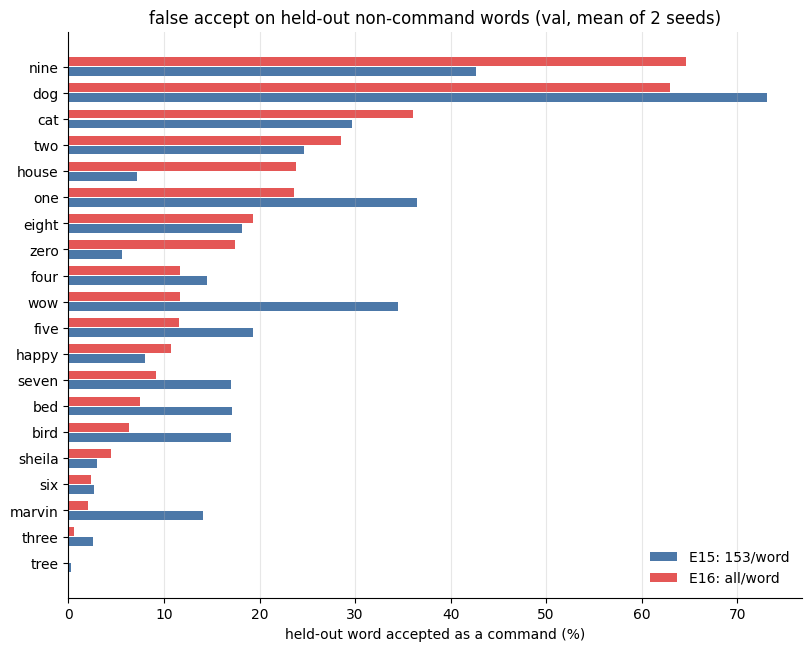

In [7]:
# 셀 7. 단어마다: 학습에서 뺐을 때 명령으로 샌 비율 (시드 2개 평균), E15 대 E16
words = pd.DataFrame(WORD_ROWS)
w_rate = words.groupby(["단어", "번호"])["샌 비율"].mean().unstack("번호")
w_top = words[words.시드 == SEEDS[0]].pivot(index="단어", columns="번호", values="가장 많이 간 명령")
w_tab = w_rate.join(w_top.add_suffix(" 가장 많이 간 명령 (시드 0)")).sort_values(list(CONDS)[-1], ascending=False)
print(w_tab.to_string(float_format=lambda v: f"{v:.2%}"))

order = w_rate.sort_values(list(CONDS)[-1]).index
fig, ax = plt.subplots(figsize=(8, 6.4), constrained_layout=True)
yy = np.arange(len(order)); hgt = 0.38
colors = {"E15": "#4C78A8", "E16": "#E45756"}               # 08의 E10r·E13과 같은 색
for k, (eid, n) in enumerate(CONDS.items()):
    ax.barh(yy + (k - 0.5) * hgt, w_rate.loc[order, eid] * 100, height=hgt - 0.04, color=colors[eid],
            label=f"{eid}: {n if n else 'all'}/word")
ax.set_yticks(yy); ax.set_yticklabels(order)
ax.set_xlabel("held-out word accepted as a command (%)")
ax.set_title("false accept on held-out non-command words (val, mean of 2 seeds)")
ax.grid(axis="x", alpha=.3); ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower right")
os.makedirs("figs", exist_ok=True)
fig.savefig("figs/09_heldout_words.png", dpi=150)
plt.show()

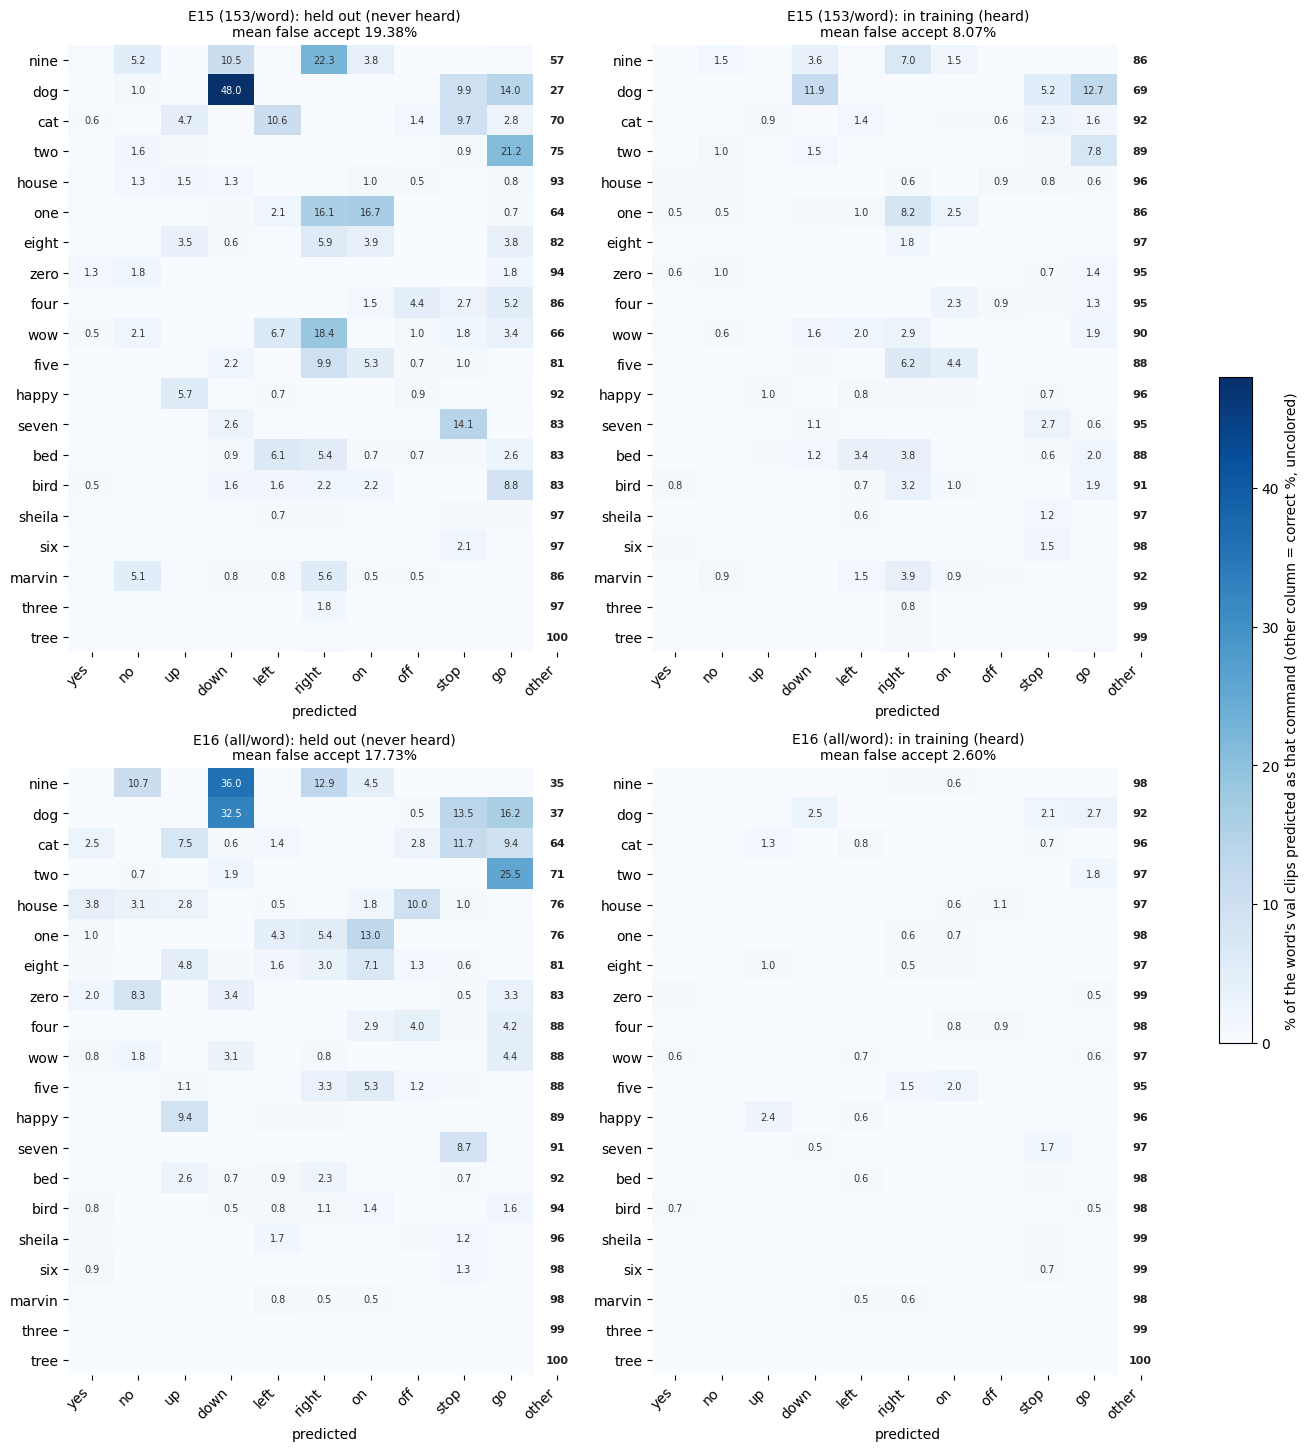

    단어 E15 들었을 때 E15 처음                E15 처음일 때 많이 간 명령 E16 들었을 때 E16 처음                 E16 처음일 때 많이 간 명령
  nine     14.2%  42.7% right 22.3%, down 10.5%, no 5.2%      2.0%  64.6% down 36.0%, right 12.9%, no 10.7%
   dog     30.5%  73.1%  down 48.0%, go 14.0%, stop 9.9%      8.0%  62.9%  down 32.5%, go 16.2%, stop 13.5%
   cat      8.0%  29.7%   left 10.6%, stop 9.7%, up 4.7%      4.0%  36.1%      stop 11.7%, go 9.4%, up 7.5%
   two     11.1%  24.6%     go 21.2%, no 1.6%, stop 0.9%      2.8%  28.6%      go 25.5%, down 1.9%, no 0.7%
 house      4.2%   7.2%      up 1.5%, down 1.3%, no 1.3%      3.0%  23.8%      off 10.0%, yes 3.8%, no 3.1%
   one     13.6%  36.5% on 16.7%, right 16.1%, left 2.1%      2.1%  23.6%   on 13.0%, right 5.4%, left 4.3%
 eight      3.1%  18.2%     right 5.9%, on 3.9%, go 3.8%      2.6%  19.4%      on 7.1%, up 4.8%, right 3.0%
  zero      4.6%   5.6%       no 1.8%, go 1.8%, yes 1.3%      1.5%  17.4%       no 8.3%, down 3.4%, go 3.3%
  four      5.3%  14.5%     

In [8]:
# 셀 8. 단어 × 예측 표 ("명령 아님" 줄을 단어 20개로 펼친 혼동 행렬)
# 행 = "명령 아님" 단어, 열 = 모델의 예측 11개, 칸 = 그 단어 녹음 중 몇 %가 그 예측으로 갔나
# 학습에서 뺐을 때(처음 듣는 단어 흉내, 1묶음 × 시드 2개 평균) 대 학습에 들었을 때(3묶음 × 시드 2개 평균)
WORDS = sorted(DIGITS + AUX)
def word_matrix(eid, heldout):
    M = np.zeros((len(WORDS), K))
    for wi, w in enumerate(WORDS):
        mw = VAL_WORD == w
        rs = [r for r in RUNS if r["번호"] == eid and ((w in r["held"]) == heldout)]
        M[wi] = np.mean([np.bincount(r["pred"][mw], minlength=K) / mw.sum() * 100 for r in rs], axis=0)
    return M
MATS = {(eid, ho): word_matrix(eid, ho) for eid in CONDS for ho in [True, False]}

oth = L2I[OTHER]
last = list(CONDS)[-1]
order = np.argsort(-(100 - MATS[(last, True)][:, oth]))          # 마지막 조건(E16)에서 뺐을 때 많이 샌 단어부터
vmax = max(np.delete(M, oth, axis=1).max() for M in MATS.values())
fig, axes = plt.subplots(len(CONDS), 2, figsize=(13, 7.2 * len(CONDS)), constrained_layout=True)
for row, eid in enumerate(CONDS):
    for col, ho in enumerate([True, False]):
        ax = axes[row, col]
        M = MATS[(eid, ho)][order]
        E = M.copy(); E[:, oth] = np.nan                              # other 열(맞힌 비율)은 색 없이 숫자만
        im = ax.imshow(E, cmap="Blues", vmin=0, vmax=vmax, aspect="auto")
        for i in range(len(WORDS)):
            for j in range(K):
                v = M[i, j]
                if j == oth:
                    ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8, fontweight="bold", color="#222")
                elif v >= 0.5:
                    ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=7, color="white" if v > vmax * 0.6 else "#333")
        ax.set_xticks(range(K)); ax.set_xticklabels(LABELS, rotation=45, ha="right")
        ax.set_yticks(range(len(WORDS))); ax.set_yticklabels(np.array(WORDS)[order])
        n = CONDS[eid]
        ax.set_title(f"{eid} ({n if n else 'all'}/word): " + ("held out (never heard)" if ho else "in training (heard)")
                     + f"\nmean false accept {100 - M[:, oth].mean():.2f}%", fontsize=10)
        ax.set_xlabel("predicted")
        for s_ in ax.spines.values():
            s_.set_visible(False)
fig.colorbar(im, ax=axes, shrink=0.5, label="% of the word's val clips predicted as that command (other column = correct %, uncolored)")
os.makedirs("figs", exist_ok=True)
fig.savefig("figs/09_word_confusion.png", dpi=150)
plt.show()

# 같은 내용을 표로: 단어마다 들었을 때 대 처음 들을 때 오작동, 많이 간 명령 상위 3개 (처음 들을 때)
rows = []
for wi in order:
    w = WORDS[wi]
    d = {"단어": w}
    for eid in CONDS:
        Mh, Ms = MATS[(eid, True)][wi], MATS[(eid, False)][wi]
        d[f"{eid} 들었을 때"] = f"{100 - Ms[oth]:.1f}%"
        d[f"{eid} 처음"] = f"{100 - Mh[oth]:.1f}%"
        top = [j for j in np.argsort(-Mh) if j != oth][:3]
        d[f"{eid} 처음일 때 많이 간 명령"] = ", ".join(f"{LABELS[j]} {Mh[j]:.1f}%" for j in top if Mh[j] > 0) or "-"
    rows.append(d)
print(pd.DataFrame(rows).to_string(index=False))